# Model comparison — fire/smoke alarm

This notebook compares the experiments trained with `src/train/train.py`:
**{original, CLAHE} × {MobileNetV3-Large, EfficientNetB0, ConvNeXt-Tiny, EfficientNetB4}**.

It only reads what the training script saved in `results/<experiment>/` (`metrics.json`, `history.csv`,
`predictions_val.csv`, `predictions_test.csv`); it does not train or run any model. Experiments that have
not been trained yet are listed and skipped.

**Task:** binary alarm — positive = fire and/or smoke, negative = no_fire.
**Threshold:** chosen on val as the best-precision threshold with recall ≥ target (95 %), applied unchanged to test.

**Contents**
1. Summary table (test metrics at the chosen threshold)
2. Original vs CLAHE per model
3. Statistical comparison: bootstrap confidence intervals and McNemar test
4. ROC and precision–recall curves
5. Alarm rate per subtype (smoke only, fire only, fire + smoke, background)
6. Quality vs speed
7. Confusion matrices
8. Training curves
9. Val vs test: does the recall target hold?
10. Ranking

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)

## 0. Configuration

In [2]:
# Locate the project root (the folder that contains `data/`), wherever the notebook is run from
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RESULTS_DIR = PROJECT_ROOT / "results"
CONFIGS_DIR = PROJECT_ROOT / "src" / "train" / "configs"

# Fixed order and names, used the same way in every table and chart
MODELS = ["mobilenetv3large", "efficientnetb0", "convnexttiny", "efficientnetb4"]
MODEL_NAMES = {"mobilenetv3large": "MobileNetV3-L", "efficientnetb0": "EfficientNetB0",
               "convnexttiny": "ConvNeXt-T", "efficientnetb4": "EfficientNetB4"}
DATASETS = ["original", "clahe"]
SUBTYPES = ["smoke_only", "fire_only", "fire_and_smoke", "background"]

# Colours: one per dataset version (same as the CLAHE notebook); models are told apart by position / label
COLORS = {"original": "#2a78d6", "clahe": "#eb6834"}
TEXT, MUTED, GRID = "#1f1f1c", "#6b6b66", "#e4e4df"

N_BOOTSTRAP = 1000
SEED = 42

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": TEXT,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

## 1. Load the results

An experiment is loaded if its folder contains `metrics.json`. The expected experiments are the ones with a
config file in `src/train/configs/`.

In [3]:
expected = sorted(p.stem for p in CONFIGS_DIR.glob("*.json"))
runs = {}
for name in expected:
    folder = RESULTS_DIR / name
    if not (folder / "metrics.json").is_file():
        continue
    runs[name] = {
        "metrics": json.loads((folder / "metrics.json").read_text()),
        "history": pd.read_csv(folder / "history.csv"),
        "val": pd.read_csv(folder / "predictions_val.csv"),
        "test": pd.read_csv(folder / "predictions_test.csv"),
    }

missing = [n for n in expected if n not in runs]
print(f"{len(runs)}/{len(expected)} experiments with results in {RESULTS_DIR}")
if missing:
    print("not trained yet:", ", ".join(missing))
if not runs:
    raise SystemExit("No results yet: train with  python src/train/train.py --config src/train/configs/<name>.json")


def order_key(name):
    m = runs[name]["metrics"]
    return MODELS.index(m["model"]), DATASETS.index(m["dataset"])


names = sorted(runs, key=order_key)
models_present = [m for m in MODELS if any(runs[n]["metrics"]["model"] == m for n in names)]


def run_of(model, dataset):
    name = f"{model}_{dataset}"
    return runs.get(name)

2/8 experiments with results in /home/campo/containers/fire-detection/results
not trained yet: convnexttiny_clahe, convnexttiny_original, efficientnetb0_clahe, efficientnetb0_original, efficientnetb4_original, mobilenetv3large_original


## 2. Summary table

Test metrics at the threshold chosen on val. `fpr` is the false alarm rate on images without fire or smoke.
`img/s` is the model-only throughput on the GPU (no disk I/O) with the training batch size.

In [4]:
rows = []
for name in names:
    m = runs[name]["metrics"]
    t, s = m["test"], m["speed"]
    rows.append({
        "model": MODEL_NAMES[m["model"]], "dataset": m["dataset"],
        "threshold": t["threshold"], "recall": t["recall"], "precision": t["precision"],
        "specificity": t["specificity"], "fpr": t["false_positive_rate"], "f1": t["f1"],
        "accuracy": t["accuracy"], "roc_auc": t["roc_auc"], "pr_auc": t["pr_auc"],
        "img/s": s["images_per_second"], "latency_ms": s["latency_ms_batch1"],
        "params_M": s["params_millions"], "best_epoch": m["best_epoch"], "train_min": m["train_minutes"],
    })
summary = pd.DataFrame(rows).set_index(["model", "dataset"])

HIGHER_IS_BETTER = ["recall", "precision", "specificity", "f1", "accuracy", "roc_auc", "pr_auc", "img/s"]
LOWER_IS_BETTER = ["fpr", "latency_ms"]
display(summary.style.format("{:.3f}")
        .format("{:.0f}", subset=["img/s", "best_epoch"]).format("{:.1f}", subset=["latency_ms", "params_M", "train_min"])
        .highlight_max(subset=HIGHER_IS_BETTER, props="font-weight:bold; background-color:#e6f0fb")
        .highlight_min(subset=LOWER_IS_BETTER, props="font-weight:bold; background-color:#e6f0fb"))

,,threshold,recall,precision,specificity,fpr,f1,accuracy,roc_auc,pr_auc,img/s,latency_ms,params_M,best_epoch,train_min
model,dataset,,,,,,,,,,,,,,
MobileNetV3-L,clahe,0.728,0.949,0.982,0.980,0.020,0.965,0.963,0.992,0.994,374,166.6,3.0,24,4.8
EfficientNetB4,clahe,0.823,0.932,0.992,0.992,0.008,0.961,0.960,0.995,0.996,25,476.0,17.7,14,76.3


## 3. Original vs CLAHE per model

Each row is a model; the two dots are its original and CLAHE versions, joined by a line.
The longer the line, the bigger the effect of CLAHE. Note the axes are zoomed in to show the differences.

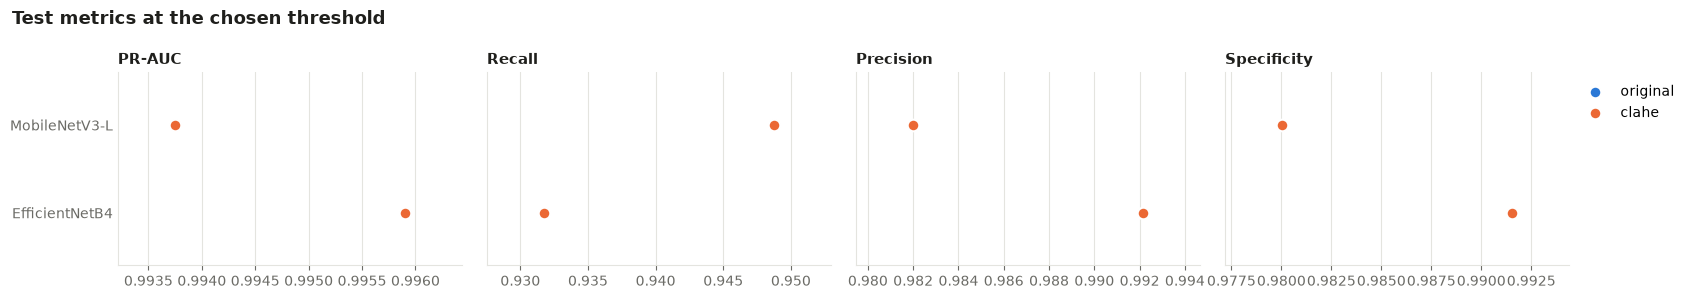

In [5]:
def dumbbell(table, columns, suptitle, percent=False):
    # One panel per column; per model, the original and CLAHE values joined by a line
    fig, axes = plt.subplots(1, len(columns), figsize=(17, 0.6 * len(models_present) + 1.8), sharey=True)
    y = np.arange(len(models_present))[::-1]
    for ax, (key, title) in zip(axes, columns):
        values = {d: [table[key].get((MODEL_NAMES[m], d), np.nan) for m in models_present] for d in DATASETS}
        for k in range(len(models_present)):
            ax.plot([values["original"][k], values["clahe"][k]], [y[k], y[k]], color=GRID, linewidth=3, zorder=1)
        for d in DATASETS:
            ax.scatter(values[d], y, s=70, color=COLORS[d], edgecolor="white", linewidth=1.5, zorder=3, label=d)
        ax.set_title(title)
        ax.margins(x=0.25)
        if percent:
            ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=1))
        ax.grid(axis="y", visible=False)
        ax.tick_params(axis="y", length=0)
    axes[0].set_yticks(y, [MODEL_NAMES[m] for m in models_present])
    axes[0].set_ylim(-0.6, len(models_present) - 0.4)
    axes[-1].legend(loc="upper left", bbox_to_anchor=(1, 1))
    fig.suptitle(suptitle, x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXT)
    fig.tight_layout()
    plt.show()


METRICS = [("pr_auc", "PR-AUC"), ("recall", "Recall"), ("precision", "Precision"), ("specificity", "Specificity")]
dumbbell(summary, METRICS, "Test metrics at the chosen threshold")

# Difference CLAHE - original (positive = CLAHE better, except fpr)
delta = []
for m in models_present:
    o, c = (MODEL_NAMES[m], "original"), (MODEL_NAMES[m], "clahe")
    if o in summary.index and c in summary.index:
        delta.append((summary.loc[c, ["recall", "precision", "specificity", "fpr", "f1", "roc_auc", "pr_auc"]]
                      - summary.loc[o, ["recall", "precision", "specificity", "fpr", "f1", "roc_auc", "pr_auc"]])
                     .rename(MODEL_NAMES[m]))
if delta:
    print("CLAHE − original (positive = higher with CLAHE; for fpr, negative is better):")
    display(pd.DataFrame(delta).style.format("{:+.3f}").background_gradient(cmap="RdBu", vmin=-0.05, vmax=0.05,
                                                                             subset=["recall", "precision", "specificity", "f1", "roc_auc", "pr_auc"]))

## 4. Is the difference real? Statistical comparison

The test set has ~4,300 images, so small differences can be noise.

- **Bootstrap 95 % confidence intervals:** the test set is resampled with replacement many times and the metric is
  recomputed each time. If the intervals of two experiments overlap a lot, the difference is not reliable.
- **McNemar test (original vs CLAHE, same model):** compares the two versions on the *same* images, looking only at
  the images where one is right and the other is wrong. p < 0.05 means the difference in errors is significant.

In [6]:
rng = np.random.default_rng(SEED)


def bootstrap_ci(y, prob, threshold, n=N_BOOTSTRAP):
    idx = rng.integers(0, len(y), size=(n, len(y)))
    pr_auc, recall, fpr = [], [], []
    for i in idx:
        yt, pt = y[i], prob[i]
        pred = pt >= threshold
        pr_auc.append(average_precision_score(yt, pt))
        recall.append(pred[yt == 1].mean())
        fpr.append(pred[yt == 0].mean())
    q = lambda v: np.percentile(v, [2.5, 97.5])
    return {"pr_auc": q(pr_auc), "recall": q(recall), "fpr": q(fpr)}


ci_rows = []
for name in names:
    m, test = runs[name]["metrics"], runs[name]["test"]
    ci = bootstrap_ci(test["alarm"].values, test["prob"].values, m["test"]["threshold"])
    ci_rows.append({"model": MODEL_NAMES[m["model"]], "dataset": m["dataset"],
                    **{f"{k}": f"{m['test'][k if k != 'fpr' else 'false_positive_rate']:.3f}  "
                               f"[{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci.items()}})
print(f"Test metrics with bootstrap 95% CI ({N_BOOTSTRAP} resamples):")
display(pd.DataFrame(ci_rows).set_index(["model", "dataset"]))

mc_rows = []
for m in models_present:
    o, c = run_of(m, "original"), run_of(m, "clahe")
    if o is None or c is None:
        continue
    merged = o["test"].merge(c["test"], on="image", suffixes=("_o", "_c"))
    right_o = (merged["prob_o"] >= o["metrics"]["test"]["threshold"]).astype(int) == merged["alarm_o"]
    right_c = (merged["prob_c"] >= c["metrics"]["test"]["threshold"]).astype(int) == merged["alarm_c"]
    only_o, only_c = int((right_o & ~right_c).sum()), int((~right_o & right_c).sum())
    p = binomtest(only_c, only_o + only_c, 0.5).pvalue if only_o + only_c else 1.0
    mc_rows.append({"model": MODEL_NAMES[m], "only original right": only_o, "only CLAHE right": only_c,
                    "p_value": p, "significant (p<0.05)": "yes" if p < 0.05 else "no",
                    "better": ("CLAHE" if only_c > only_o else "original") if p < 0.05 else "—"})
if mc_rows:
    print("McNemar test (exact), original vs CLAHE on the test set:")
    display(pd.DataFrame(mc_rows).set_index("model"))

Test metrics with bootstrap 95% CI (1000 resamples):


,,pr_auc,recall,fpr
model,dataset,,,
MobileNetV3-L,clahe,"0.994 [0.992, 0.995]","0.949 [0.940, 0.957]","0.020 [0.014, 0.026]"
EfficientNetB4,clahe,"0.996 [0.995, 0.997]","0.932 [0.922, 0.942]","0.008 [0.005, 0.013]"


## 5. ROC and precision–recall curves

One panel per model, original and CLAHE overlaid. The dot marks the operating point at the chosen threshold.
In the ROC curves the x axis is cut at 30 % false alarms to zoom into the useful region.

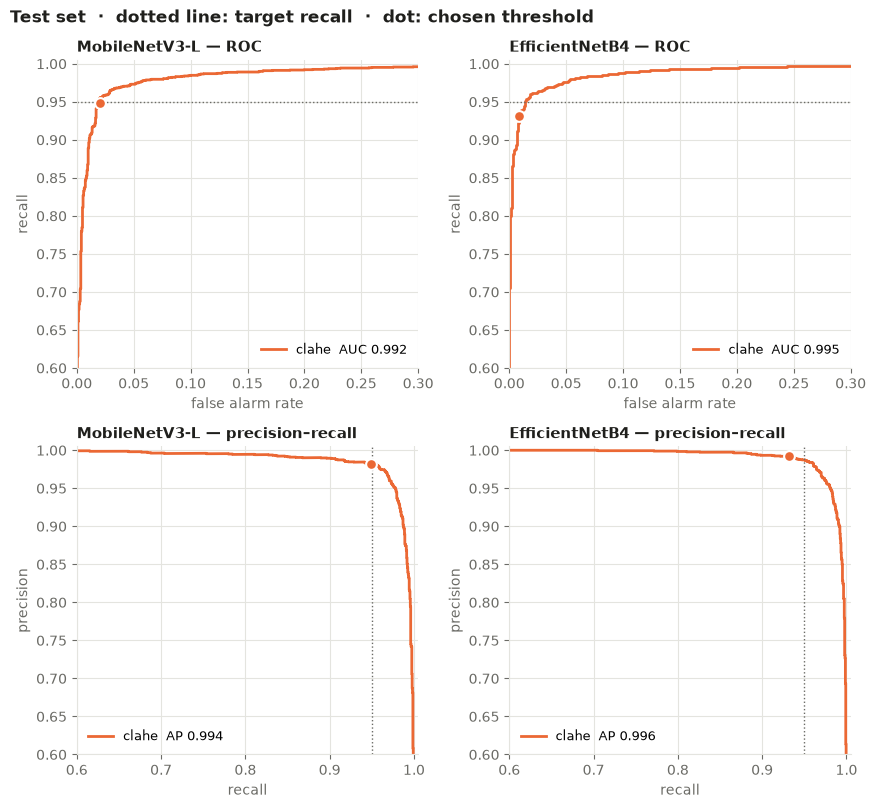

In [7]:
fig, axes = plt.subplots(2, len(models_present), figsize=(4.4 * len(models_present), 8.2), squeeze=False)
for col, m in enumerate(models_present):
    ax_roc, ax_pr = axes[0, col], axes[1, col]
    for d in DATASETS:
        run = run_of(m, d)
        if run is None:
            continue
        y, p, thr = run["test"]["alarm"].values, run["test"]["prob"].values, run["metrics"]["test"]["threshold"]
        fpr, tpr, _ = roc_curve(y, p)
        prec, rec, _ = precision_recall_curve(y, p)
        ax_roc.plot(fpr, tpr, color=COLORS[d], linewidth=2, label=f"{d}  AUC {roc_auc_score(y, p):.3f}")
        ax_pr.plot(rec, prec, color=COLORS[d], linewidth=2, label=f"{d}  AP {average_precision_score(y, p):.3f}")
        t = run["metrics"]["test"]
        ax_roc.scatter(t["false_positive_rate"], t["recall"], s=60, color=COLORS[d], edgecolor="white", linewidth=1.5, zorder=3)
        ax_pr.scatter(t["recall"], t["precision"], s=60, color=COLORS[d], edgecolor="white", linewidth=1.5, zorder=3)
    target = next(iter(runs.values()))["metrics"]["target_recall"]
    ax_roc.axhline(target, color=MUTED, linestyle=":", linewidth=1)
    ax_pr.axvline(target, color=MUTED, linestyle=":", linewidth=1)
    ax_roc.set(title=f"{MODEL_NAMES[m]} — ROC", xlabel="false alarm rate", ylabel="recall", xlim=(0, 0.3), ylim=(0.6, 1.005))
    ax_pr.set(title=f"{MODEL_NAMES[m]} — precision–recall", xlabel="recall", ylabel="precision", xlim=(0.6, 1.005), ylim=(0.6, 1.005))
    ax_roc.legend(loc="lower right", fontsize=9)
    ax_pr.legend(loc="lower left", fontsize=9)
fig.suptitle(f"Test set  ·  dotted line: target recall  ·  dot: chosen threshold", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=TEXT)
fig.tight_layout()
plt.show()

## 6. Alarm rate per subtype

How often the model raises the alarm for each kind of image (test set, chosen threshold):
- for **smoke only**, **fire only** and **fire + smoke** this is the recall of that subtype (higher is better);
- for **background** it is the false alarm rate (lower is better).

Smoke without visible fire is expected to be the hardest case.

Test images per subtype: smoke_only=1,186, fire_only=220, fire_and_smoke=895, background=2,005


,,smoke_only,fire_only,fire_and_smoke,background
MobileNetV3-L,clahe,91.1%,95.0%,99.8%,2.0%
EfficientNetB4,clahe,88.3%,95.9%,99.0%,0.8%


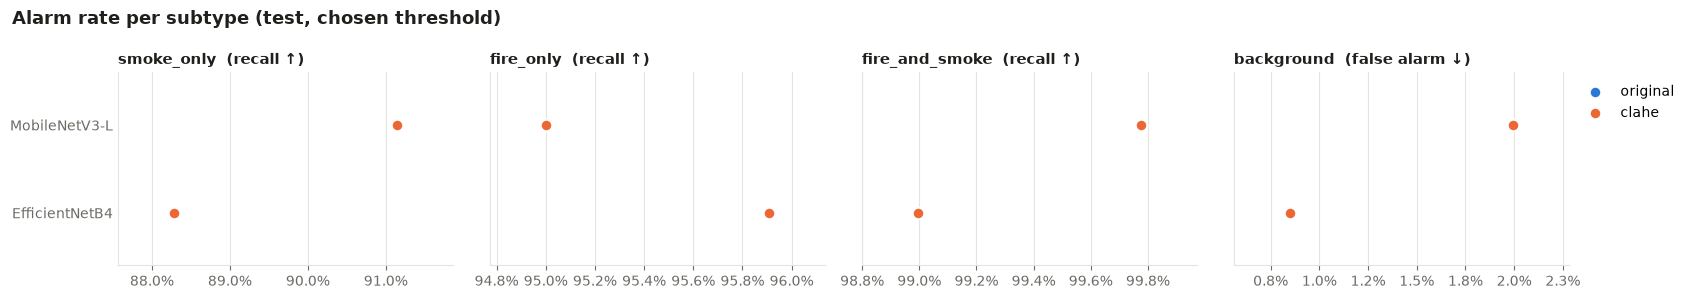

In [8]:
sub = pd.DataFrame({(MODEL_NAMES[runs[n]["metrics"]["model"]], runs[n]["metrics"]["dataset"]):
                    runs[n]["metrics"]["test_subtype_alarm_rate"] for n in names}).T.reindex(columns=SUBTYPES)
counts = next(iter(runs.values()))["test"]["subtype"].value_counts().reindex(SUBTYPES)
print("Test images per subtype:", ", ".join(f"{s}={n:,}" for s, n in counts.items()))
display(sub.style.format("{:.1%}")
        .background_gradient(cmap="Blues", vmin=0.7, vmax=1, subset=SUBTYPES[:3])
        .background_gradient(cmap="Oranges", vmin=0, vmax=0.3, subset=["background"]))

dumbbell(sub, [(s, f"{s}  ({'false alarm ↓' if s == 'background' else 'recall ↑'})") for s in SUBTYPES],
         "Alarm rate per subtype (test, chosen threshold)", percent=True)

## 7. Quality vs speed

The best model is not always the most practical one: for real-time use (cameras, edge devices) speed matters too.
The x axis is logarithmic. Models up and to the right are better on both.

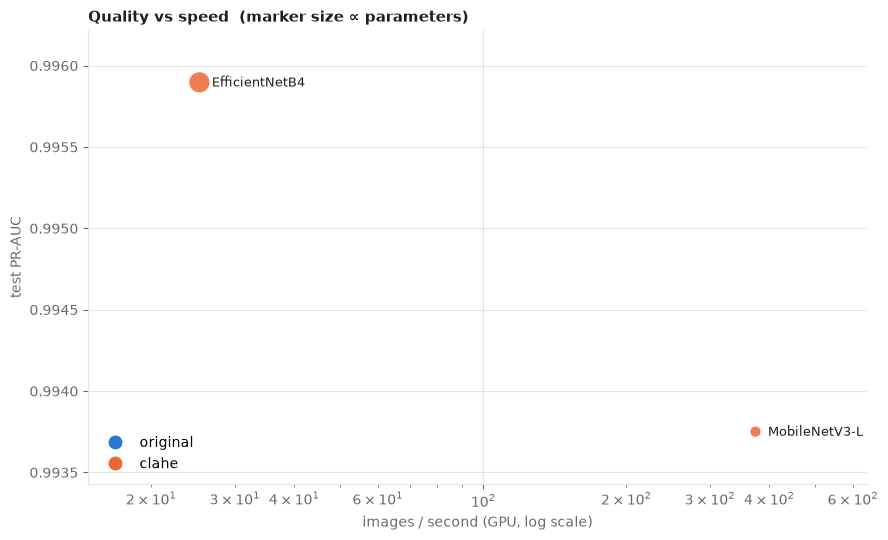

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for d in DATASETS:
    part = summary.xs(d, level="dataset") if d in summary.index.get_level_values("dataset") else None
    if part is None:
        continue
    ax.scatter(part["img/s"], part["pr_auc"], s=part["params_M"] * 12 + 40, color=COLORS[d], alpha=0.85,
               edgecolor="white", linewidth=1.5, label=d, zorder=3)
    for model_name, r in part.iterrows():
        ax.annotate(model_name, (r["img/s"], r["pr_auc"]), xytext=(9, -3), textcoords="offset points",
                    fontsize=9, color=TEXT)
ax.set_xscale("log")
ax.set_xlabel("images / second (GPU, log scale)")
ax.set_ylabel("test PR-AUC")
ax.set_title("Quality vs speed  (marker size ∝ parameters)")
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=COLORS[d], label=d) for d in DATASETS]
ax.legend(handles=handles, loc="lower left")
ax.margins(x=0.2, y=0.15)
plt.tight_layout()
plt.show()

## 8. Confusion matrices

Test set at the chosen threshold. Rows are the true class; each cell shows the count and the % of its row.
**FN** (fire/smoke predicted as no alarm, bottom left) are the missed fires; **FP** (top right) are the false alarms.

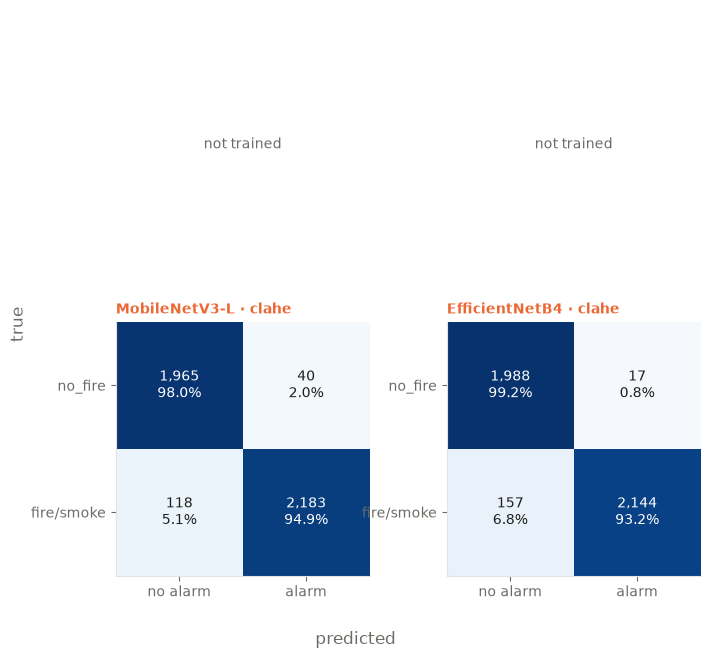

In [10]:
fig, axes = plt.subplots(len(DATASETS), len(models_present), figsize=(3.6 * len(models_present), 6.6), squeeze=False)
for col, m in enumerate(models_present):
    for row, d in enumerate(DATASETS):
        ax = axes[row, col]
        run = run_of(m, d)
        if run is None:
            ax.axis("off")
            ax.text(0.5, 0.5, "not trained", ha="center", va="center", color=MUTED, transform=ax.transAxes)
            continue
        cm = run["metrics"]["test"]["confusion_matrix"]
        mat = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
        ax.imshow(mat / mat.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for (i, j), v in np.ndenumerate(mat):
            share = v / mat[i].sum()
            ax.text(j, i, f"{v:,}\n{share:.1%}", ha="center", va="center", fontsize=10,
                    color="white" if share > 0.5 else TEXT)
        ax.set_xticks([0, 1], ["no alarm", "alarm"])
        ax.set_yticks([0, 1], ["no_fire", "fire/smoke"])
        ax.grid(False)
        ax.set_title(f"{MODEL_NAMES[m]} · {d}", color=COLORS[d], fontsize=10)
fig.supxlabel("predicted", color=MUTED)
fig.supylabel("true", color=MUTED)
fig.tight_layout()
plt.show()

## 9. Training curves

Validation PR-AUC (the metric used to keep the best weights) and validation loss per epoch.
The dotted line marks where phase 2 (fine-tuning) starts; the dot is the best epoch.
A val loss going up while train loss keeps going down is a sign of overfitting.

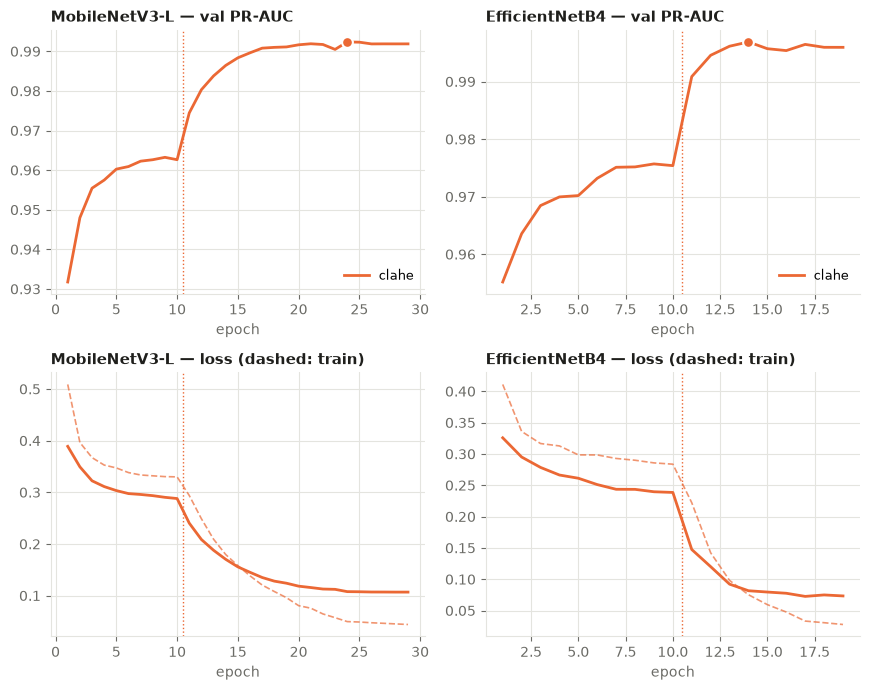

In [11]:
fig, axes = plt.subplots(2, len(models_present), figsize=(4.4 * len(models_present), 7), squeeze=False)
for col, m in enumerate(models_present):
    for d in DATASETS:
        run = run_of(m, d)
        if run is None:
            continue
        h = run["history"]
        best = h.loc[h["val_pr_auc"].idxmax()]
        axes[0, col].plot(h["epoch"], h["val_pr_auc"], color=COLORS[d], linewidth=2, label=d)
        axes[0, col].scatter(best["epoch"], best["val_pr_auc"], s=60, color=COLORS[d], edgecolor="white", linewidth=1.5, zorder=3)
        axes[1, col].plot(h["epoch"], h["loss"], color=COLORS[d], linewidth=1.2, linestyle="--", alpha=0.7)
        axes[1, col].plot(h["epoch"], h["val_loss"], color=COLORS[d], linewidth=2, label=d)
        start2 = h.loc[h["phase"] == "phase2", "epoch"].min()
        if not np.isnan(start2):
            for ax in axes[:, col]:
                ax.axvline(start2 - 0.5, color=COLORS[d], linestyle=":", linewidth=1)
    axes[0, col].set(title=f"{MODEL_NAMES[m]} — val PR-AUC", xlabel="epoch")
    axes[1, col].set(title=f"{MODEL_NAMES[m]} — loss (dashed: train)", xlabel="epoch")
    axes[0, col].legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

## 10. Val vs test: does the recall target hold?

The threshold was chosen on val to reach the target recall. If test recall falls clearly below it, the threshold
does not generalise (val and test differ, or the threshold sits on a steep part of the curve).

In [12]:
gap = pd.DataFrame([{
    "model": MODEL_NAMES[runs[n]["metrics"]["model"]], "dataset": runs[n]["metrics"]["dataset"],
    "threshold": runs[n]["metrics"]["val"]["threshold"],
    "val_recall": runs[n]["metrics"]["val"]["recall"], "test_recall": runs[n]["metrics"]["test"]["recall"],
    "val_precision": runs[n]["metrics"]["val"]["precision"], "test_precision": runs[n]["metrics"]["test"]["precision"],
    "val_pr_auc": runs[n]["metrics"]["val"]["pr_auc"], "test_pr_auc": runs[n]["metrics"]["test"]["pr_auc"],
    "test_recall_at_0.5": runs[n]["metrics"]["test_at_0.5"]["recall"],
} for n in names]).set_index(["model", "dataset"])
gap["target_met"] = np.where(gap["test_recall"] >= next(iter(runs.values()))["metrics"]["target_recall"] - 0.01, "yes", "no")
display(gap)

,,threshold,val_recall,test_recall,val_precision,test_precision,val_pr_auc,test_pr_auc,test_recall_at_0.5,target_met
model,dataset,,,,,,,,,
MobileNetV3-L,clahe,0.728,0.951,0.949,0.977,0.982,0.994,0.994,0.967,yes
EfficientNetB4,clahe,0.823,0.950,0.932,0.990,0.992,0.997,0.996,0.964,no


## 11. Ranking

Experiments sorted by test PR-AUC (threshold-independent quality), with the operating-point metrics next to it.
When two experiments are within each other's confidence intervals (section 4), prefer the faster or simpler one.

In [13]:
ranking = summary[["pr_auc", "roc_auc", "recall", "precision", "fpr", "f1", "img/s", "params_M"]] \
    .sort_values("pr_auc", ascending=False)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
display(ranking.style.format("{:.3f}").format("{:.0f}", subset=["rank", "img/s"]).format("{:.1f}", subset=["params_M"]))

best = ranking.index[0]
print(f"Best by test PR-AUC: {best[0]} ({best[1]})  —  PR-AUC {ranking.iloc[0]['pr_auc']:.3f}, "
      f"recall {ranking.iloc[0]['recall']:.3f}, false alarms {ranking.iloc[0]['fpr']:.1%}, {ranking.iloc[0]['img/s']:.0f} img/s")

,,rank,pr_auc,roc_auc,recall,precision,fpr,f1,img/s,params_M
model,dataset,,,,,,,,,
EfficientNetB4,clahe,1,0.996,0.995,0.932,0.992,0.008,0.961,25,17.7
MobileNetV3-L,clahe,2,0.994,0.992,0.949,0.982,0.020,0.965,374,3.0


Best by test PR-AUC: EfficientNetB4 (clahe)  —  PR-AUC 0.996, recall 0.932, false alarms 0.8%, 25 img/s


## How to read the results

- **Choose the model with val, report with test.** This notebook shows test metrics to compare, but the test set
  should not be used to tune anything (threshold, hyperparameters). If you change something because of what you
  see here, the test result is no longer an unbiased estimate.
- **CLAHE helps** if the CLAHE version is better for most models *and* the McNemar test is significant. A small
  gain within the confidence intervals is not evidence.
- **Smoke only** is usually the weak point: if its recall is much lower than the others, that is where to focus
  (more data, augmentation, higher resolution).
- **Operating point:** recall vs false alarms is a trade-off set by the threshold; the ROC/PR curves show what
  other operating points each model could reach.